# 0. Overview — End-to-End Agentic Ontology Walkthrough
## 5-Stage × 9-Step Lifecycle · BigQuery Property Graph (ISO GQL) · AI FDE Agent

본 노트북은 **Agentic Ontology Starter Pack v2.0**의 전체 흐름(`0. Overview` + `Stage 1` ~ `Stage 5`)을 실환경 BigQuery(`seanjung-poc.starter_ontology_dw`)와 Vertex AI(`gemini-3.8-flash`) 위에서 한눈에 탐색·시각화·실행하는 종합 가이드입니다.

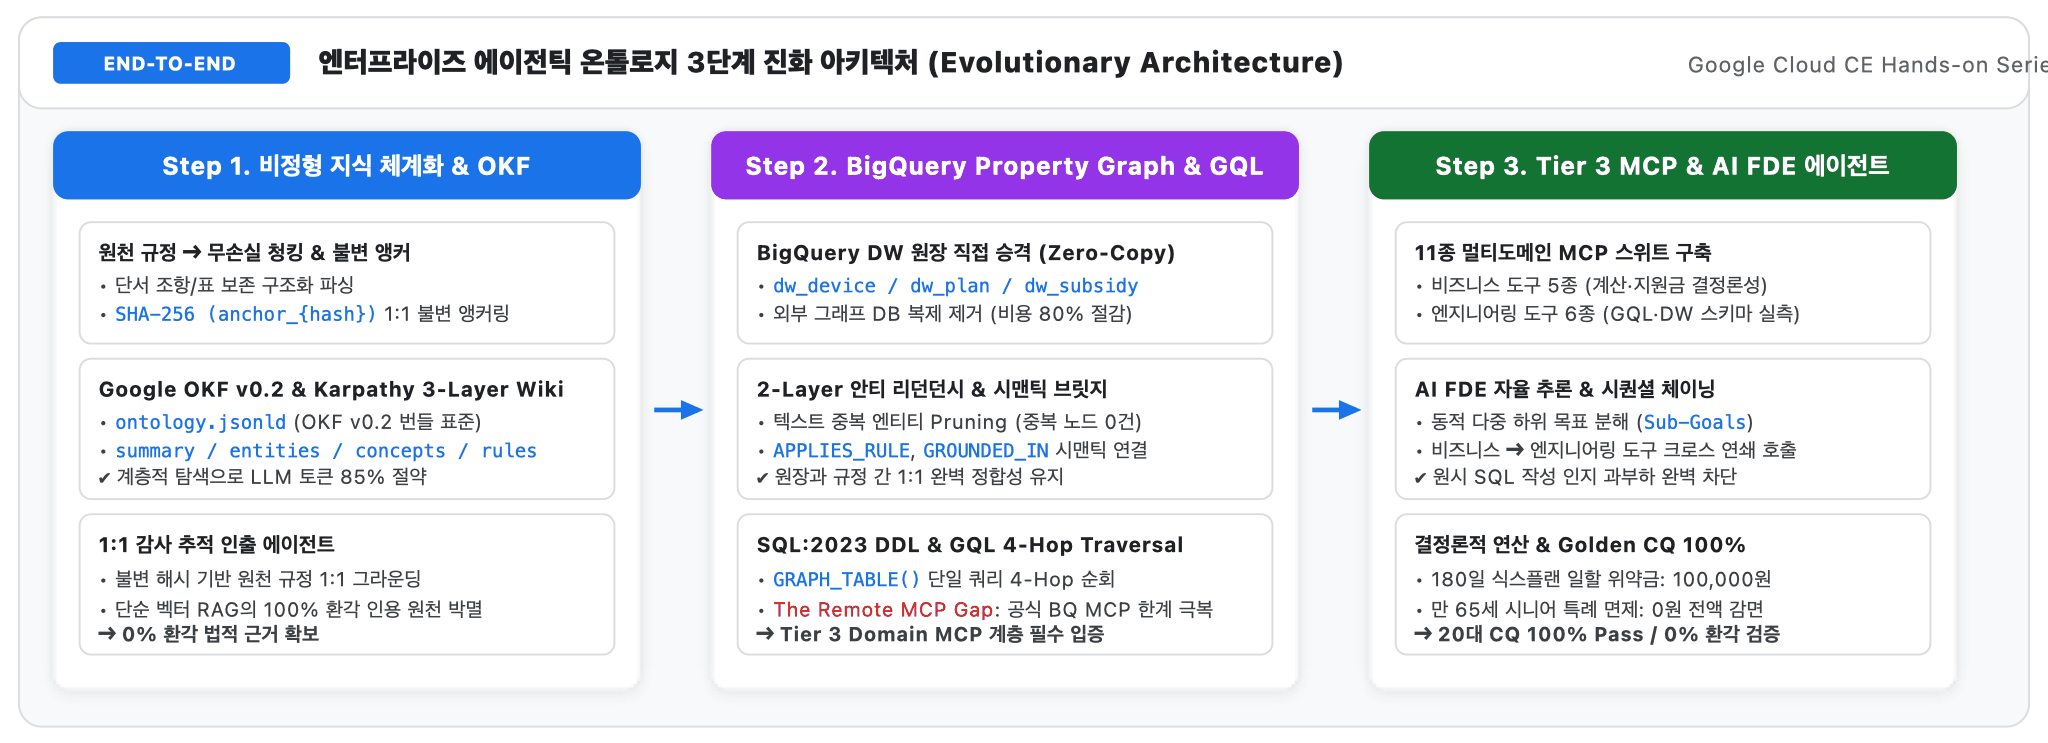

| 트랙 (Track) | 실행 Stage 구성 | 대상 환경 및 목적 |
| :--- | :--- | :--- |
| **Track 1 · Lite** | `Stage 1 → Stage 2 → Stage 4` | 정형 그래프 없이 비정형 정책 문서 위키(3-Layer LLM-Wiki)만으로 즉시 에이전트 구동 |
| **Track 2 · Standard** | `Stage 1 → Stage 2 → Stage 3 → Stage 4` | 정형 DW 원장 4종 + 비정형 규칙을 듀얼 Property Graph(BigQuery / Spanner)로 결합 |
| **Track 3 · Full-Stack** | `Stage 1 → Stage 2 → Stage 3 → Stage 4 → Stage 5` | 4-Tier 데이터 리니지 및 Golden CQ 5건 / Boundary 10건 회귀 평가까지 전 주기 운영 |


In [1]:
%load_ext bigframes
import nb_helpers as H
H.setup("ko")


,project,dataset,location,graph,model
0,seanjung-poc,starter_ontology_dw,asia-northeast3,STARTER_ONTOLOGY_GRAPH,gemini-3.8-flash


### 1. BigQuery 데이터셋(`starter_ontology_dw`) 10개 물리 테이블 프로파일링 (`%%bqsql`)


In [2]:
%%bqsql df_tables
SELECT table_id, row_count, size_bytes,
  CASE WHEN STARTS_WITH(table_id, 'edge_') THEN 'edge'
       WHEN table_id IN ('tb_doc_chunks', 'tb_domain_rules') THEN 'knowledge'
       ELSE 'master' END AS kind
FROM `seanjung-poc.starter_ontology_dw.__TABLES__`
ORDER BY kind, table_id


,table_id,row_count,size_bytes,kind
0,edge_contract_device,6,368,edge
1,edge_contract_plan,6,379,edge
2,edge_rule_applies_to_plan,12,1450,edge
3,edge_subsidy_binding,5,342,edge
4,tb_doc_chunks,5,2784,knowledge
5,tb_domain_rules,4,1858,knowledge
6,tb_customer_contract,6,856,master
7,tb_device_master,4,292,master
8,tb_plan_master,6,423,master
9,tb_subsidy_policy,5,382,master


,table_id,row_count,size_bytes,kind
0,edge_contract_device,6,368,edge
1,edge_contract_plan,6,379,edge
2,edge_rule_applies_to_plan,12,1450,edge
3,edge_subsidy_binding,5,342,edge
4,tb_doc_chunks,5,2784,knowledge
5,tb_domain_rules,4,1858,knowledge
6,tb_customer_contract,6,856,master
7,tb_device_master,4,292,master
8,tb_plan_master,6,423,master
9,tb_subsidy_policy,5,382,master


findfont: Failed to find font weight bold for AppleGothic, now using 400.


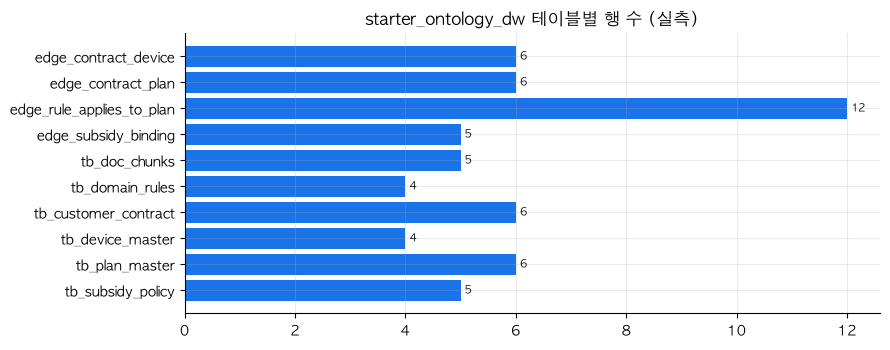

In [3]:
H.show(df_tables)
H.bar(df_tables, "table_id", "row_count", "starter_ontology_dw 테이블별 행 수 (실측)", horizontal=True)


### 2. BigQuery Property Graph(`STARTER_ONTOLOGY_GRAPH`) 전체 경로 추출 및 토폴로지 시각화 (`%%bqsql` + ISO GQL)


In [4]:
%%bqsql df_paths
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH p = (a)-[e]->(b)
RETURN TO_JSON(p) AS path


,path
0,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
1,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
2,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
3,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
4,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
5,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
6,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
7,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
8,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."
9,"""[{\""identifier\"":\""riMAAAANAAAApgAAAAAAAAAArB..."


**추출된 그래프 노드 `19`개 · 엣지 `29`개**

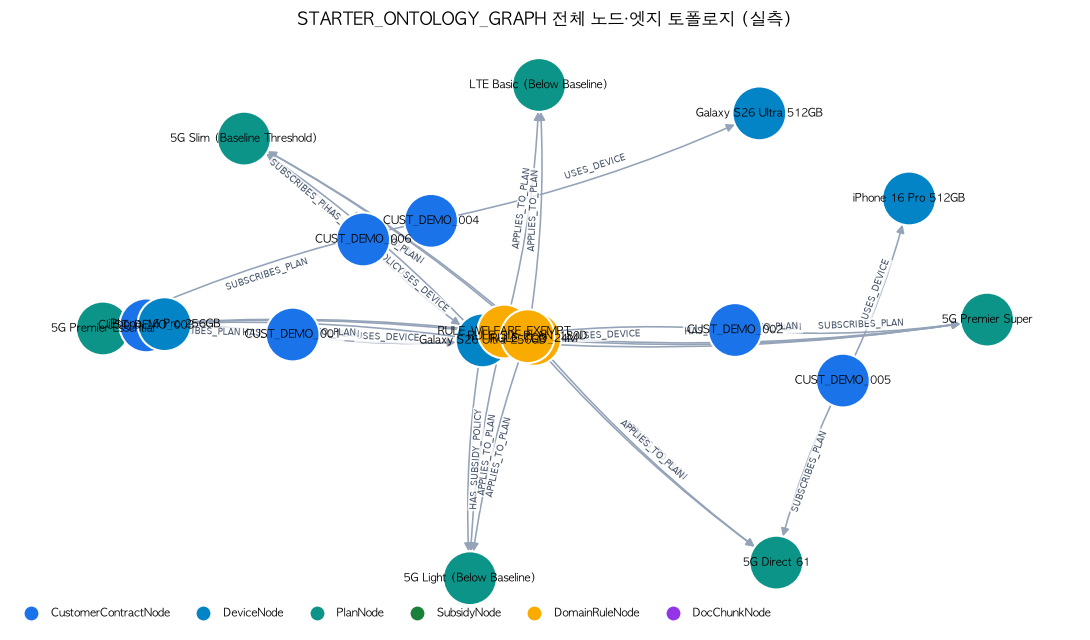

In [5]:
nodes, edges = H.paths_to_graph(H.pdf(df_paths)["path"])
H.md(f"**추출된 그래프 노드 `{len(nodes)}`개 · 엣지 `{len(edges)}`개**")
H.draw_graph(nodes, edges, "STARTER_ONTOLOGY_GRAPH 전체 노드·엣지 토폴로지 (실측)", legend=H.LABEL_COLORS)


### 3. 자연어 질의 → ISO GQL 자동 생성 및 BigQuery 실행 (`nl2gql`)


In [6]:
node_labels, edge_labels, _ = H.graph_metadata()
schema_str = H.schema_text(node_labels, edge_labels)
_ = H.nl2gql("각 고객이 사용 중인 단말기명과 가입 요금제명, 월정액을 고객 ID 순으로 보여줘", schema_str)


**Q.** 각 고객이 사용 중인 단말기명과 가입 요금제명, 월정액을 고객 ID 순으로 보여줘
- Gemini `gemini-3.8-flash`: 고객 계약 노드와 연결된 단말기 및 요금제 노드를 매칭하여 고객별 단말기명, 요금제명, 월정액을 조회합니다. (토큰 1,343, 6,101 ms)

시도 1 · status `SUCCESS` · job `job_kwbvo6_8jYB-a85wtinMInzzG9kU` · 682 ms · 6 rows
```sql
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH` MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode) RETURN c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw ORDER BY customer_id LIMIT 50
```

,customer_id,device_name,plan_name,monthly_fee_krw
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,85000
1,CUST_DEMO_002,Galaxy S26 Ultra 256GB,5G Premier Super,130000
2,CUST_DEMO_003,iPhone 16 Pro 256GB,5G Premier Essential,85000
3,CUST_DEMO_004,Galaxy S26 Ultra 512GB,5G Premier Essential,85000
4,CUST_DEMO_005,iPhone 16 Pro 512GB,5G Direct 61,61000
5,CUST_DEMO_006,Galaxy S26 Ultra 256GB,5G Slim (Baseline Threshold),45000


### 4. AI FDE 에이전트 2-Pass 추론 및 결정론적 MCP 체이닝 (Golden CQ-03 & CQ-05)


In [7]:
from src.agent.reasoning_engine import AiFdeAgentEngine
agent = AiFdeAgentEngine()
H.show_agent(agent.execute_cycle("CUST_DEMO_001 고객이 개통 120일 시점에 5G Light(37,000원)로 하향 시 위약금과 근거 앵커는?"), "Golden CQ-03 · 120일 일할 위약금 산출")
H.show_agent(agent.execute_cycle("CUST_DEMO_003(시니어 복지 대상) 고객이 개통 88일차에 시니어 요금제로 변경 시 위약금 면제 여부와 그래프 경로 확인해줘"), "Golden CQ-05 · 시니어 복지 면제 & 그래프 경로")


#### Golden CQ-03 · 120일 일할 위약금 산출
**Q.** CUST_DEMO_001 고객이 개통 120일 시점에 5G Light(37,000원)로 하향 시 위약금과 근거 앵커는?

- 응답 상태: `GROUNDED` · Gemini `gemini-3.8-flash` 2 calls · 토큰 6,496 · LLM 14,254 ms · 총 17.34 s
- 추출 파라미터: `{"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "5G Light"}`

| # | MCP | status | rows | BigQuery ms | Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 563 | `job_qlGiY1APwndl43foqO-xCrJ3vK55` |
| 2 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 1,261 | `job_0XKkyblwqIhSSBylGaQn7W8ylQZ6`, `job_BYGw525wsq9zLXvFIelmgqVSUzYf` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 783 | `job_P5mRQ4YZHVzyIO4-dTDt8-uRTMzD` |

**에이전트 답변**

> ### **결론**
> CUST_DEMO_001 고객이 개통 120일 시점에 월 37,000원 요금제(5G Light)로 하향 변경할 경우 발생하는 **위약금(차액정산금)은 100,000원**입니다. 
>
> 근거 앵커는 **`DOC_CHUNK_002` (anchor: `anchor_3003b683cea0`)** 및 **`DOC_CHUNK_003` (anchor: `anchor_47971ec8e4d8`)**입니다.
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> 1. **고객 및 계약 기본 정보**
>    - **고객 ID**: CUST_DEMO_001 (계약 ID: CONTRACT_DEMO_101)
>    - **가입 유형**: 공시지원금 약정 (PUBLIC_SUBSIDY)
>    - **복지/면제 자격**: NONE (해당 없음)
>    - **경과 일수**: 120일 (의무 유지 기간: 180일)
>    - **현재 요금제**: 5G Premier Essential (월 85,000원 / 기본 지원금: 450,000원)
>    - **하향 대상 요금제**: 5G Light (월 37,000원 / 기본 지원금: 150,000원)
>    - **기준선 요금**: 월 45,000원
>
> 2. **위약금 산식 및 계산 결과**
>    - **적용 규칙**: `RULE_SIX_PLAN_180D`
>    - **조건**: 개통 180일 미만(`elapsed_days < 180`)이며, 기준선 미만 요금제로 하향(`target_plan_monthly_fee < 45000`)
>    - **산식**: 
>      $$\text{위약금} = \text{ROUND}\left((\text{기존 기본지원금} - \text{변경 요금제 기본지원금}) \times \frac{180 - \text{경과일수}}{180}\right)$$
>    - **계산**:
>      $$(450,000\text{원} - 150,000\text{원}) \times \frac{180 - 120}{180} = 300,000\text{원} \times \frac{60}{180} = \mathbf{100,000\text{원}}$$
>
> ---
>
> ### **규칙·원문 근거**
>
> - **RULE_SIX_PLAN_180D**
>   - **규칙명**: 180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙
>   - **도메인 규칙 청크**: `DOC_CHUNK_003` (앵커: `anchor_47971ec8e4d8`)
>   - **그래프 및 원문 청크**: `DOC_CHUNK_002` (섹션: Baseline Plan Commitment (Six-Plan Rule), 앵커: `anchor_3003b683cea0`)
>   - **원문 내용**: 공시지원금 수혜 가입자는 개통일로부터 180일간 기준선 요금제(5G 45,000원/월) 이상을 유지해야 하며, 180일 이내 하향 시 경과 일수에 따른 일할 차액정산 위약금이 부과됩니다.
>
> ---
>
> ### **실행 정보**
> - **mcp_lookup_customer_profile Job ID**: `job_qlGiY1APwndl43foqO-xCrJ3vK55`
> - **mcp_calculate_penalty_rule Job ID**: `job_0XKkyblwqIhSSBylGaQn7W8ylQZ6`, `job_BYGw525wsq9zLXvFIelmgqVSUzYf`
> - **mcp_query_graph_and_wiki Job ID**: `job_P5mRQ4YZHVzyIO4-dTDt8-uRTMzD`

#### Golden CQ-05 · 시니어 복지 면제 & 그래프 경로
**Q.** CUST_DEMO_003(시니어 복지 대상) 고객이 개통 88일차에 시니어 요금제로 변경 시 위약금 면제 여부와 그래프 경로 확인해줘

- 응답 상태: `GROUNDED` · Gemini `gemini-3.8-flash` 2 calls · 토큰 6,745 · LLM 16,009 ms · 총 18.44 s
- 추출 파라미터: `{"customer_id": "CUST_DEMO_003", "elapsed_days": 88, "target_plan_mention": "시니어 요금제"}`

| # | MCP | status | rows | BigQuery ms | Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 637 | `job_iawhr4EdcnNFFM81ldM6cjFKR4jB` |
| 2 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 1,158 | `job_sKoAOQUid1yY4hx4d06zMq_UOs7k`, `job_4vuZm24po1vI84iI3mL0zDT5BGqa` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 634 | `job_tINdQCIFYGhtllu5TJPOtx8Wr6Ji` |

**에이전트 답변**

> ### **결론**
> 고객 CUST_DEMO_003은 개통 88일차에 시니어 요금제로 변경하더라도 **위약금이 전액 면제(0원)**됩니다.  
> 해당 고객은 복지 특례 상태인 `SENIOR_EXEMPT`로 등록되어 있어, 180일 의무 유지 기간 미경과 상태라도 시니어 요금제 전환 시 차액정산 위약금 면제 규정이 적용됩니다.
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> 1. **고객 및 계약 프로필**
>    - **고객 ID**: CUST_DEMO_003 (연령대: 65+, 세그먼트: Senior_Welfare)
>    - **계약 ID**: CONTRACT_DEMO_103
>    - **복지 특례 상태**: `SENIOR_EXEMPT`
>    - **약정 유형 / 기간**: 공시지원금 약정(`PUBLIC_SUBSIDY`) / 24개월
>    - **경과 일수**: 88일 (의무유지일수: 180일)
>    - **단말기 정보**: iPhone 16 Pro 256GB (출고가 1,700,000원)
>    - **현재 요금제**: 5G Premier Essential (월 85,000원)
>    - **지급 지원금**: 총 460,000원 (기본 공시지원금 400,000원 + 유통망 추가지원금 60,000원)
>
> 2. **위약금 계산 결과**
>    - **면제 판정 상태**: `EXEMPT_WELFARE`
>    - **부과 위약금**: **0원**
>    - **산식**: `penalty = 0 (SENIOR_EXEMPT 대상)`
>
> 3. **온톨로지 그래프 탐색 경로**
>    - **그래프 엔진 / 명칭**: BigQuery (`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`)
>    - **GQL 경로 패턴**: `(c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)`
>    - **탐색 홉 수 / 매칭 노드 수**: 3홉 / 4개
>    - **연결된 규칙 경로**:
>      - `CONTRACT_DEMO_103` → `5G Premier Essential` ← [180일 기준선 유지 의무 적용] ← `RULE_SIX_PLAN_180D`
>      - `CONTRACT_DEMO_103` → `5G Premier Essential` ← [24개월 공시 vs 선택약정 비교 적용] ← `RULE_TCO_24M`
>
> ---
>
> ### **규칙·원문 근거**
>
> - **RULE_WELFARE_EXEMPT** (`DOC_CHUNK_004`, 앵커: `anchor_269d9c42e05c`)
>   - **규칙명**: 시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례
>   - **조건식**: `welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')`
>   - **내용**: 만 65세 이상 시니어 복지 특례(SENIOR_EXEMPT) 대상자가 시니어/복지 요금제로 전환 시 180일 이내라도 차액정산 위약금을 100% 면제(0원)함.
> - **RULE_SIX_PLAN_180D** (`DOC_CHUNK_002`, `DOC_CHUNK_003`, 앵커: `anchor_3003b683cea0`, `anchor_47971ec8e4d8`)
>   - **내용**: 180일 기준선(월정액 45,000원) 미만으로 하향 변경 시 차액정산금이 부과되는 일반 원칙이나, 상위 복지 특례(`RULE_WELFARE_EXEMPT`)에 의해 면제됨.
> - **RULE_SUBSIDY_CAP** (`DOC_CHUNK_001`, 앵커: `anchor_a52e1a72869f`)
>   - **내용**: 공시지원금 및 유통망 추가지원금(15%) 합산 규칙 적용(총 460,000원).
> - **RULE_TCO_24M** (`DOC_CHUNK_005`, 앵커: `anchor_4fbaf9c5cba8`)
>   - **내용**: 24개월 공시지원금 총비용(3,280,000원) 대비 선택약정 총비용(3,230,000원) 비교 산출 규칙.
>
> ---
>
> ### **실행 정보**
>
> - **고객 프로필 조회**: `job_iawhr4EdcnNFFM81ldM6cjFKR4jB` (소요 시간: 637.11ms)
> - **위약금 규칙 연산**: `job_sKoAOQUid1yY4hx4d06zMq_UOs7k`, `job_4vuZm24po1vI84iI3mL0zDT5BGqa` (소요 시간: 1157.88ms)
> - **그래프 및 위키 탐색**: `job_tINdQCIFYGhtllu5TJPOtx8Wr6Ji` (소요 시간: 634.09ms)